# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [4]:
df = pd.read_csv(
    r"E:\data visulization\data-viz-class-material-w2026\data\co2_emissions.csv"
)

print(df.head())

         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [5]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv(
    r"E:\data visulization\data-viz-class-material-w2026\data\co2_emissions.csv"
)

print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 345 rows
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [6]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

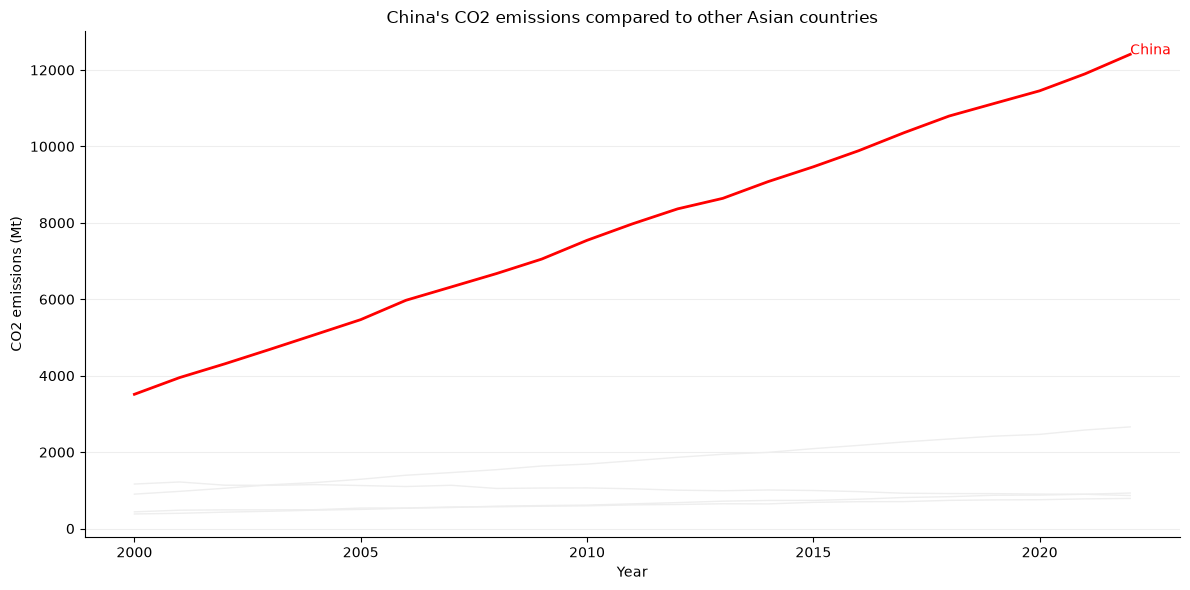

In [8]:
# Task - Multi-series line with highlight

import matplotlib.pyplot as plt

asia = df[df["Region"] == "Asia"]

plt.figure(figsize=(12, 6))

# Show all countries in grey
for country, data in asia.groupby("Country"):
    plt.plot(data["Year"], data["CO2_Mt"], color="#EEEEEE", linewidth=1)

# Highlight China
china = asia[asia["Country"] == "China"]
plt.plot(china["Year"], china["CO2_Mt"], color="red", linewidth=2)

# Label China at the end
last = china.iloc[-1]
plt.text(last["Year"], last["CO2_Mt"], "China", color="red")

# Title and labels
plt.title("China's CO2 emissions compared to other Asian countries")
plt.xlabel("Year")
plt.ylabel("CO2 emissions (Mt)")

# Remove chart borders and heavy gridlines
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#EEEEEE")

plt.tight_layout()
plt.show()